<a href="https://colab.research.google.com/github/kaz3107/IS4487/blob/main/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [27]:
# Load historical data
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/adviseinvest_historical_data.csv"

df = pd.read_csv(url)

# Preview data
display(df.head())

# Check data structure
df.info()

# Summary statistics
display(df.describe(include='all'))

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# Check numeric ranges for possible outliers
display(df.describe())

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,14850.475563,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000


Missing values:
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

Duplicate rows: 3


,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. I noticed a few unusual values in the data. Income has a negative minimum value, age goes up to 132, and num_accts has a maximum of 3,345, which seems very high. I also noticed that new_car has a few missing values. These are things I would check and clean before building the model.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [28]:
# Create a clean copy
df_clean = df.copy()

# Remove duplicates
df_clean = df_clean.drop_duplicates()

# Remove obvious outliers
df_clean = df_clean[df_clean['income'] >= 0]
df_clean = df_clean[df_clean['age'].between(18, 100)]
df_clean = df_clean[df_clean['num_accts'] < 100]

# Fill missing new_car values with the mode
df_clean['new_car'] = df_clean['new_car'].fillna(
    df_clean['new_car'].mode()[0]
)

# Remove variables that should not be used for prediction
df_clean = df_clean.drop(columns=['customer_id', 'product'])

# Check cleaned data
print(df_clean.shape)
print(df_clean.isnull().sum())
display(df_clean.describe(include='all'))

(29497, 13)
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
count,29497.000000,29497.000000,29497,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000
unique,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,27898,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.546700,33775.860596,NaN,34.770994,1.915449,1.141031,0.210360,0.681154,0.240770,1.468319,0.956572,2.345323,0.091128
std,0.497823,29373.742541,NaN,11.355178,0.658217,0.348060,0.407571,0.466037,0.427558,1.234706,1.483996,1.200626,0.287796
min,0.000000,2760.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
50%,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000
75%,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed values that seemed unrealistic, such as negative income, very high age, and unusually high numbers of accounts. I also filled the missing new_car values with the most common value. I chose this approach so the unusual or missing values would not affect the model too much.

2.6 I removed customer_id because it is only an identifier and does not describe customer behavior. I also removed product because it is only known after the customer answers, so it would not be useful for predicting whether a customer will answer.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [29]:
# Convert answered to boolean
df_clean['answered'] = df_clean['answered'].astype(bool)

# Convert new_car to integer
df_clean['new_car'] = df_clean['new_car'].astype(int)

# Fix unusual value in female
df_clean['female'] = pd.to_numeric(df_clean['female'], errors='coerce')
df_clean = df_clean.dropna(subset=['female'])
df_clean['female'] = df_clean['female'].astype(int)

# Check data types
df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,int64
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,int64


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [30]:
# Convert appropriate variables to categorical
df_clean['job'] = df_clean['job'].astype('category')
df_clean['chk_acct'] = df_clean['chk_acct'].astype('category')
df_clean['sav_acct'] = df_clean['sav_acct'].astype('category')

# Check updated data types
df_clean.dtypes

print(df_clean.shape)
print(df_clean['female'].value_counts())
df_clean.dtypes

(29496, 13)
female
0    27898
1     1598
Name: count, dtype: int64


,0
answered,bool
income,int64
female,int64
age,int64
job,category
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,category


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



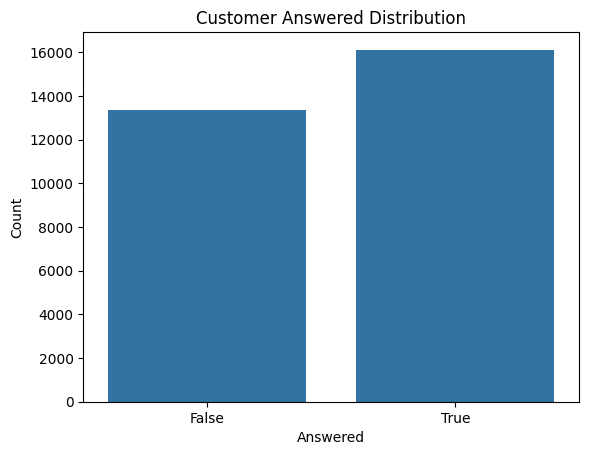

In [31]:
# Chart 3.1 🔧
sns.countplot(data=df_clean, x='answered')

plt.title("Customer Answered Distribution")
plt.xlabel("Answered")
plt.ylabel("Count")
plt.show()

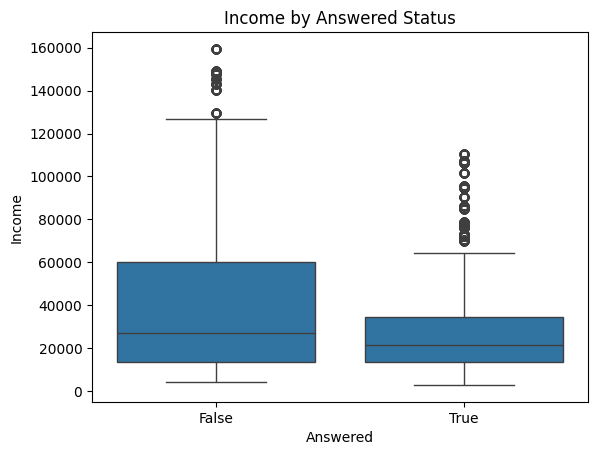

In [32]:
# Chart 3.2 🔧
sns.boxplot(data=df_clean, x='answered', y='income')

plt.title("Income by Answered Status")
plt.xlabel("Answered")
plt.ylabel("Income")
plt.show()

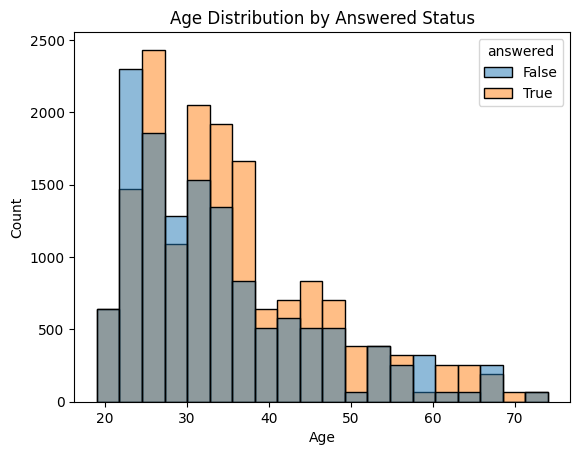

In [33]:
# Chart 3.3 🔧
sns.histplot(data=df_clean, x='age', hue='answered', bins=20)

plt.title("Age Distribution by Answered Status")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

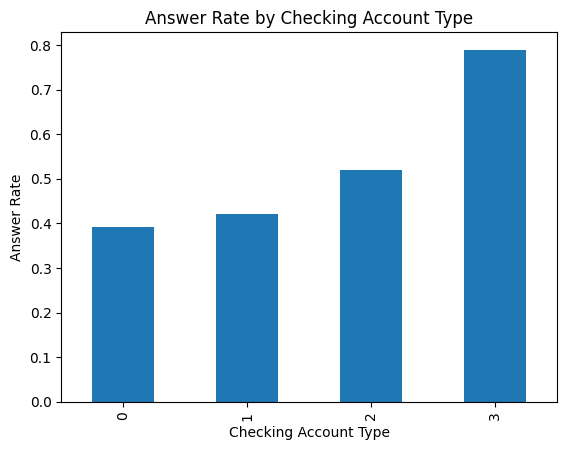

In [34]:
# Chart 3.4 🔧
answer_rate = df_clean.groupby('chk_acct', observed=True)['answered'].mean()

answer_rate.plot(kind='bar')

plt.title("Answer Rate by Checking Account Type")
plt.xlabel("Checking Account Type")
plt.ylabel("Answer Rate")
plt.show()

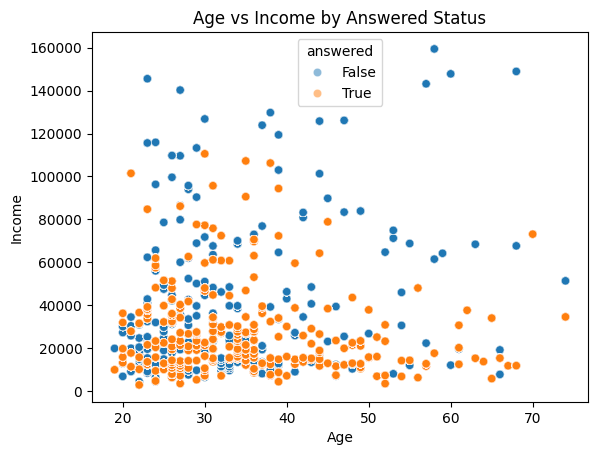

In [35]:
# Chart 3.5 🔧
sns.scatterplot(
    data=df_clean,
    x='age',
    y='income',
    hue='answered',
    alpha=0.5
)

plt.title("Age vs Income by Answered Status")
plt.xlabel("Age")
plt.ylabel("Income")
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. I think chk_acct shows the strongest relationship with answered because the answer rate changes a lot across the different checking account categories. Income also seems to have some relationship with whether a customer answered.

3.7. Age seems to have a weaker relationship because the two groups overlap a lot. However, I would not remove it yet because it may still be useful when combined with other variables in the model.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [36]:
# Calculate base probability of answering
base_probability = df_clean['answered'].mean()

print("Base probability of answering:", base_probability)
print("Percentage:", base_probability * 100)

Base probability of answering: 0.546718199077841
Percentage: 54.671819907784105


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [37]:
# Encode categorical variables
df_model = pd.get_dummies(
    df_clean,
    columns=['job', 'chk_acct', 'sav_acct'],
    drop_first=False
)

# Select X and y
X = df_model.drop(columns=['answered'])
y = df_model['answered']

print("X shape:", X.shape)
print("y shape:", y.shape)

from sklearn.model_selection import train_test_split

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

X shape: (29496, 22)
y shape: (29496,)
Training: (23596, 22)
Testing: (5900, 22)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

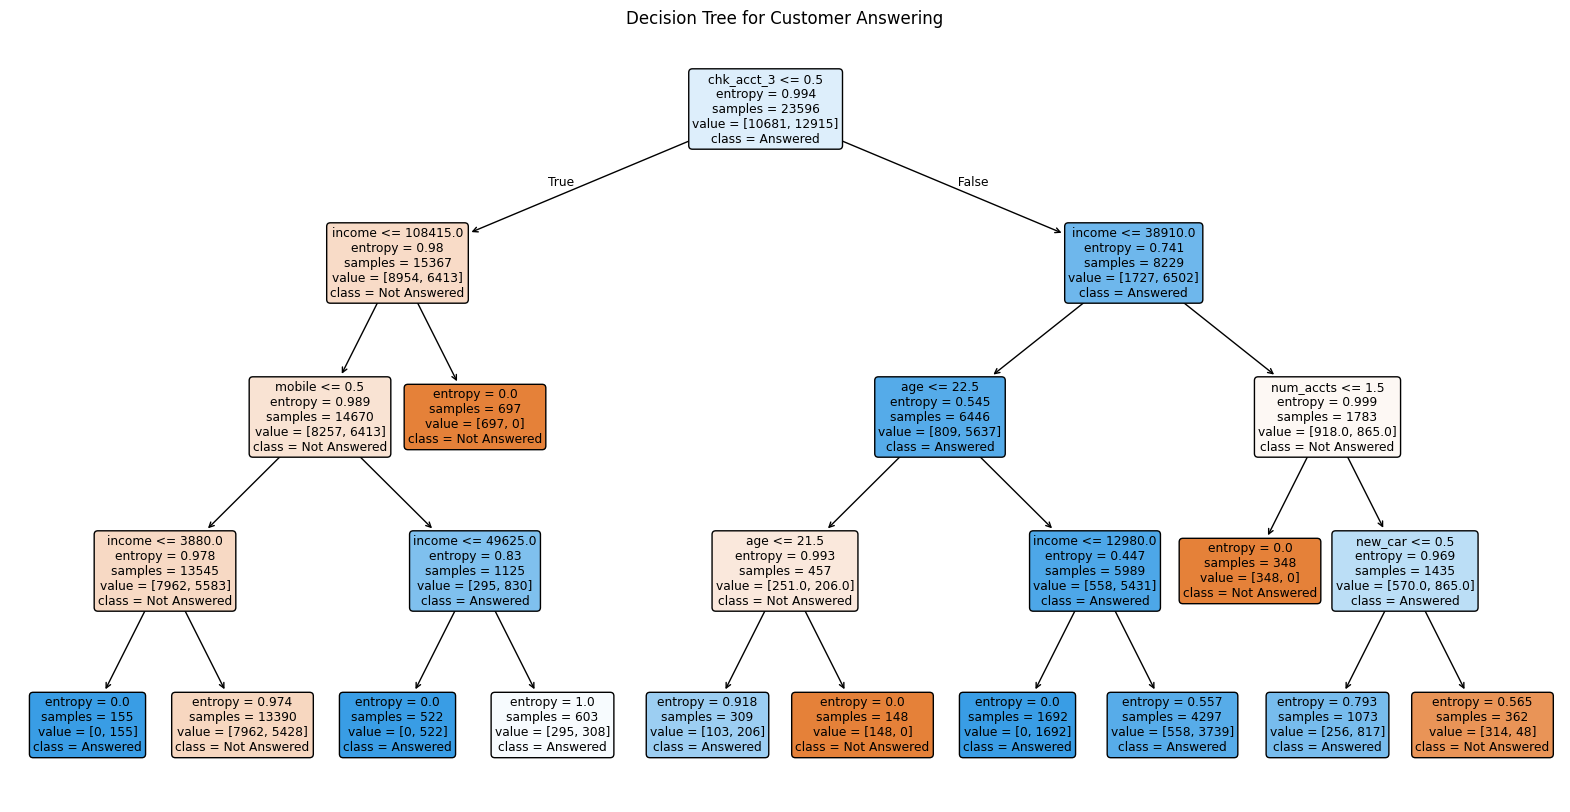

In [38]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Create decision tree
tree_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=4,
    random_state=42
)

# Train the model
tree_model.fit(X_train, y_train)

# Visualize the tree
plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=['Not Answered', 'Answered'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree for Customer Answering")
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [39]:
from sklearn.metrics import accuracy_score

# Predict on test data
y_pred = tree_model.predict(X_test)

# Calculate model accuracy
tree_accuracy = accuracy_score(y_test, y_pred)

print("Base Probability:", base_probability)
print("Tree Accuracy:", tree_accuracy)
print("Improvement:", tree_accuracy - base_probability)

Base Probability: 0.546718199077841
Tree Accuracy: 0.7125423728813559
Improvement: 0.16582417380351488


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The model accuracy is about 71.25%, compared to the base probability of about 54.67%. This is an improvement of about 16.58 percentage points.

2. I think this is a significant improvement because the model is much better than simply using the base probability. This could help the business identify customers who are more likely to answer.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [40]:
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2365  324]
 [1372 1839]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

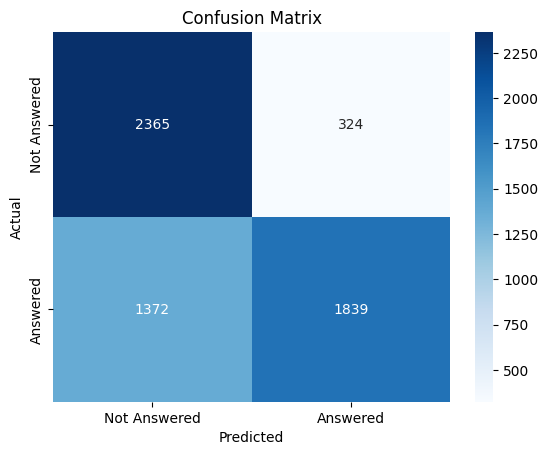

In [41]:
# Visualize confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Answered', 'Answered'],
    yticklabels=['Not Answered', 'Answered']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [42]:
# Get values from confusion matrix
tn, fp, fn, tp = cm.ravel()

# Calculate profit using the model
model_profit = (tp * 75) - (fp * 25)

print("True Positives:", tp)
print("False Positives:", fp)
print("Profit using model: $", model_profit)

True Positives: 1839
False Positives: 324
Profit using model: $ 129825


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [43]:
# If all customers in the test set are called
all_answered = y_test.sum()
all_not_answered = len(y_test) - all_answered

# Calculate baseline profit
default_profit = (all_answered * 75) - (all_not_answered * 25)

# Compare profits
profit_difference = model_profit - default_profit

print("Profit calling all customers: $", default_profit)
print("Profit using model: $", model_profit)
print("Profit improvement: $", profit_difference)

Profit calling all customers: $ 173600
Profit using model: $ 129825
Profit improvement: $ -43775


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling all customers produced $173,600 in profit, while using the model produced $129,825. This means the model made $43,775 less profit than calling everyone.

2. I think this is a significant difference because the model actually reduced profit. Even though the model had better prediction accuracy, it missed many customers who would have answered, so accuracy alone did not lead to a better business result.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [44]:
# Try different max_depth values
for depth in range(2, 11):
    test_model = DecisionTreeClassifier(
        criterion='entropy',
        max_depth=depth,
        random_state=42
    )

    test_model.fit(X_train, y_train)
    test_pred = test_model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)

    print("Max Depth:", depth, "- Accuracy:", test_acc)

# Create new tree with the best depth
tree_tuned = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=10,
    random_state=42
)

# Train the new model
tree_tuned.fit(X_train, y_train)

# Check new accuracy
y_pred_tuned = tree_tuned.predict(X_test)
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("\nOriginal Tree Accuracy:", tree_accuracy)
print("Tuned Tree Accuracy:", tuned_accuracy)

Max Depth: 2 - Accuracy: 0.6572881355932203
Max Depth: 3 - Accuracy: 0.6928813559322033
Max Depth: 4 - Accuracy: 0.7125423728813559
Max Depth: 5 - Accuracy: 0.7338983050847457
Max Depth: 6 - Accuracy: 0.7630508474576271
Max Depth: 7 - Accuracy: 0.7705084745762711
Max Depth: 8 - Accuracy: 0.7788135593220339
Max Depth: 9 - Accuracy: 0.7808474576271186
Max Depth: 10 - Accuracy: 0.800677966101695

Original Tree Accuracy: 0.7125423728813559
Tuned Tree Accuracy: 0.800677966101695


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [45]:
# Load new customer data
new_url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(new_url)

# Remove duplicates
df_new = df_new.drop_duplicates()

# Handle missing values
df_new['new_car'] = df_new['new_car'].fillna(
    df_new['new_car'].mode()[0]
)

# Remove outliers
df_new = df_new[df_new['income'] >= 0]
df_new = df_new[df_new['age'].between(18, 100)]
df_new = df_new[df_new['num_accts'] < 100]

# Fix female and convert data types
df_new['female'] = pd.to_numeric(df_new['female'], errors='coerce')
df_new = df_new.dropna(subset=['female'])
df_new['female'] = df_new['female'].astype(int)
df_new['new_car'] = df_new['new_car'].astype(int)

# Remove customer_id
df_new = df_new.drop(columns=['customer_id'])

# Convert categorical variables
df_new['job'] = df_new['job'].astype('category')
df_new['chk_acct'] = df_new['chk_acct'].astype('category')
df_new['sav_acct'] = df_new['sav_acct'].astype('category')

# Encode categorical variables
df_new = pd.get_dummies(
    df_new,
    columns=['job', 'chk_acct', 'sav_acct'],
    drop_first=False
)

# Match columns with training data
df_new = df_new.reindex(columns=X.columns, fill_value=0)

# Predict new customers using the tuned model
new_predictions = tree_tuned.predict(df_new)

# Count predictions
print(pd.Series(new_predictions).value_counts())

True     624
False    376
Name: count, dtype: int64


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1. No, the model did not improve profit in this case. Calling all customers made $173,600, while using the model made $129,825. The model missed some customers who would have answered, which reduced the total profit.

6.2. The business could use the model to identify customers who are more likely to answer and prioritize those customers for calls. This could help save time and make the calling process more targeted, but the model would need more improvement before using it only to decide who should be called.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [46]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_10_classification.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tr